# Practice case: KaffeCaféen, suggested solution

The case was the final case exam in an earlier introductory course in Python. It brings together what you have practiced in notebooks 1 and 2 in five tasks. At the exam, students had 30 minutes and could use their notebooks and notes, but not search engines or AI tools. Feel free to try the case under the same conditions. This is the suggested solution.

## Before you start: get the data

You need the file `kaffecafeen.xlsx`. There are two ways to access it:

**Option A (upload):** Download the file from the [data](https://github.com/aaubs/AQM-2026/tree/main/python-refresher/en/data) folder in the course GitHub repository. Open the file panel on the left side of Colab (the folder icon), click the upload icon and choose `kaffecafeen.xlsx`. The file can then be loaded with the file name `"kaffecafeen.xlsx"`.

**Option B (link):** Load the file directly from the internet with the address in the variable `DATA_URL` (see the setup cell below). Then you do not need to upload anything.

Both ways give the same data. Choose the one you are most comfortable with.

## When you are done

1. Run the whole notebook from the top: the menu **Runtime > Run all** (Kørselstid > Kør alle).
2. Check that all cells show output without errors.

## The case

You have just been hired as an administrative employee at **KaffeCaféen**, a small chain of cafés with four branches in North Jutland. Your manager has sent you an extract from the cash register system for June and July 2026. Each row in the file is one **sales line**: one product sold in a certain quantity. If a customer buys, for example, a latte and a cinnamon roll, that gives two rows.

The columns are: `SaleId`, `Date`, `Branch`, `Product`, `Quantity` and `UnitPrice` (price per unit in DKK).

Your manager has asked you to create an overview of the sales. You do that in the five tasks below.

In [1]:
# The address of the data file (used in Option B, run the cell before loading the data):
DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/en/data/kaffecafeen.xlsx"

## Task 1: Load and inspect the data

Pandas is not imported in the setup cell. That is part of the task.

Write code that:
1. imports pandas with the usual alias
2. loads `kaffecafeen.xlsx` into a DataFrame named `df` (use Option A or B)
3. shows the first 5 rows of `df`
4. shows how many rows and columns `df` has

In [2]:
# === TASK 1: Solution ===

# 1. Import pandas with the alias pd
import pandas as pd


In [3]:
# 2. Load kaffecafeen.xlsx into a DataFrame named df
df = pd.read_excel(DATA_URL)

# Can also be written (Option A, requires upload): df = pd.read_excel("kaffecafeen.xlsx")

In [4]:
# 3. Show the first 5 rows
df.head()

,SaleId,Date,Branch,Product,Quantity,UnitPrice
0,1065,2026-06-01,Nørresundby,Latte,3,42
1,1165,2026-06-01,Aalborg C,Coffee,4,30
2,1177,2026-06-01,Aalborg Øst,Latte,1,42
3,1203,2026-06-01,Aalborg Øst,Coffee,2,30
4,1285,2026-06-01,Hjørring,Latte,2,42


In [5]:
# 4. Show the number of rows and columns (shape)
df.shape
# df.head() and df.shape can also stand as the last line in a cell of their own, without print

(300, 6)

In [6]:
# SAFETY NET: Run this cell, however task 1 went.
# It loads the data correctly, so you can solve tasks 2-5 even if task 1 gave you trouble.
import pandas as pd
df = pd.read_excel(DATA_URL)
print("The data is ready:", df.shape)

The data is ready: (300, 6)


## Task 2: Computed column

Your manager wants to see what each sales line has brought in.

Write code that:
1. creates a new column in `df` named `Revenue`, computed as `Quantity` times `UnitPrice`
2. shows the first 5 rows of `df`, so the new column can be seen

In [7]:
# === TASK 2: Solution ===

# 1. Create the column Revenue = Quantity * UnitPrice
df["Revenue"] = df["Quantity"] * df["UnitPrice"]


In [8]:
# 2. Show the first 5 rows of df
df.head()

,SaleId,Date,Branch,Product,Quantity,UnitPrice,Revenue
0,1065,2026-06-01,Nørresundby,Latte,3,42,126
1,1165,2026-06-01,Aalborg C,Coffee,4,30,120
2,1177,2026-06-01,Aalborg Øst,Latte,1,42,42
3,1203,2026-06-01,Aalborg Øst,Coffee,2,30,60
4,1285,2026-06-01,Hjørring,Latte,2,42,84


## Task 3: Lookup

Your manager calls and asks about one particular sales line: the one with **SaleId 1088**.

Write code that shows the row with SaleId 1088, so you can read off `Product` and `Revenue`.

*Tip: The data is not sorted by SaleId, so you need to use code, not scroll.*

In [9]:
# === TASK 3: Solution ===

# Show the row where SaleId is 1088
print(df[df["SaleId"] == 1088])
# Can also be written: df.loc[df["SaleId"] == 1088]
# Reading: Product = Tea, Revenue = 56 DKK


     SaleId       Date       Branch Product  Quantity  UnitPrice  Revenue
220    1088 2026-07-16  Aalborg Øst     Tea         2         28       56


## Task 4: Filter and compute

Your manager wants to know how the branch in **Hjørring** is doing.

Write code that:
1. selects the rows in `df` where `Branch` is `"Hjørring"`
2. computes and shows the **sum** of `Revenue` for these rows
3. computes and shows the **mean** of `Revenue` for these rows

In [10]:
# === TASK 4: Solution ===

# 1. Select the rows where Branch is "Hjørring"
hjorring = df[df["Branch"] == "Hjørring"]

In [11]:
# 2. Show the sum of Revenue for Hjørring
print(hjorring["Revenue"].sum())

5569


In [12]:
# 3. Show the mean of Revenue for Hjørring
print(hjorring["Revenue"].mean())
# Result: sum = 5569, mean = 94.39 (approx.)
# Filtering and computing can also be written in one line, e.g. df[df["Branch"] == "Hjørring"]["Revenue"].sum()

94.38983050847457


## Task 5: Visualization

For a meeting, your manager wants a picture of how the size of the sales lines is distributed.

Complete the code below so it shows a **histogram** of the column `Revenue` with 8 intervals (bins). The chart must have text on both axes and a title, so it can be understood without explanation.

In [13]:
# Import matplotlib.pyplot with the usual alias plt
import matplotlib.pyplot as plt

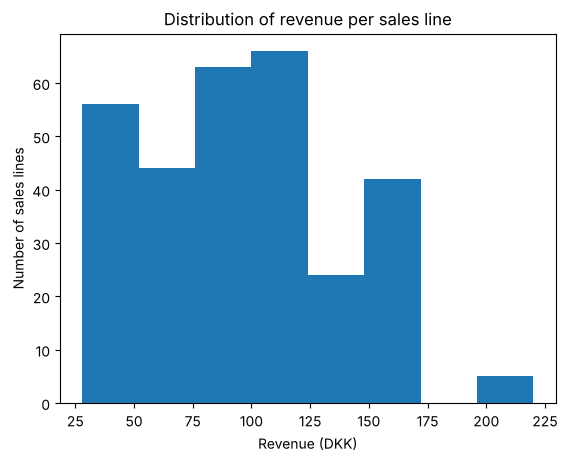

In [14]:
# === TASK 5: Solution ===

plt.hist(df["Revenue"], bins=8)
plt.xlabel("Revenue (DKK)")
plt.ylabel("Number of sales lines")
plt.title("Distribution of revenue per sales line")
plt.show()
# Other axis labels and titles are just as good, as long as all three are filled in
# and df["Revenue"] is plotted with bins=8

---

**Finally:** Run Runtime > Run all, and check that all cells show output without errors.